# 🔬 Scikit-Learn Pipeline: With PCA vs. Without PCA Comparison

This notebook demonstrates the **modular Pipeline & ColumnTransformer format** comparing two standard machine learning workflows on the exact same dataset:
1. **Pipeline 1 (With PCA)**: Includes a Principal Component Analysis dimensionality reduction step (`pca: PCA()`) with hyperparameter tuning on `n_components`.
2. **Pipeline 2 (Without PCA)**: Directly feeds all preprocessed features into the estimator.
3. **Bonus Unified Pipeline**: Tests PCA vs. 'passthrough' in a single `GridSearchCV`.

---

### End-to-End Workflow:
- **1. Data Loading & Type Splitting**: Automatic extraction of numeric and categorical features.
- **2. ColumnTransformer**: Median imputation + `StandardScaler` for numbers, Most frequent imputation + `OneHotEncoder` for categories.
- **3. Train-Test Split**: Stratified 80/20 partitioning.
- **4. Model Construction**:
  - `pipe_pca = Pipeline([('preprocessor', preprocessor), ('pca', PCA()), ('model', LogisticRegression())])`
  - `pipe_no_pca = Pipeline([('preprocessor', preprocessor), ('model', LogisticRegression())])`
- **5. Hyperparameter Tuning**: 5-Fold `GridSearchCV` on both pipelines.
- **6. Full Evaluation Metrics**: Accuracy, Precision, Recall, F1, ROC-AUC, Confusion Matrix, and ROC Curve comparison.
- **7. PCA Explained Variance Analysis**: Scree plot and dimensional trade-off analysis.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_auc_score, roc_curve
)


✓ All necessary libraries and pipeline modules imported successfully.


---
## 1. Data Loading & Preprocessing Pipeline


In [ ]:
# 1. Load dataset (Heart Disease)
df = pd.read_csv("heart.csv")

# Separate features (X) and target (y)
X = df.drop(columns=['target'])
y = df['target']

cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
num_cols = [c for c in X.columns if c not in cat_cols]


# 2. 80/20 Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"\nTrain set: {X_train.shape[0]} samples | Test set: {X_test.shape[0]} samples")

Dataset Shape: 303 rows, 14 columns
Numerical Continuous Features (5): ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical Features (8): ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

Train set: 242 samples | Test set: 61 samples


In [3]:
# 3. Construct Preprocessor with ColumnTransformer
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

# Inspect total encoded features
X_preprocessed = preprocessor.fit_transform(X_train)
print(f"✓ Total preprocessed feature dimensions before PCA: {X_preprocessed.shape[1]} columns")

✓ Total preprocessed feature dimensions before PCA: 30 columns


---
## 2. Pipeline 1: WITH PCA (Dimensionality Reduction)

In this pipeline, **PCA** is inserted between the `preprocessor` and the `model`.  
`GridSearchCV` optimizes both the number of principal components (`pca__n_components`) and the regularization strength (`model__C`).


In [4]:
# 1. Pipeline Definition: Preprocessor -> PCA -> Model
pipe_pca = Pipeline([
    ('preprocessor', preprocessor),
    ('pca', PCA()),
    ('model', LogisticRegression(max_iter=2000, random_state=42))
])

# 2. Parameter Grid for Pipeline 1
params_pca = {
    'pca__n_components': [3, 5, 8, 12],
    'model__C': [0.01, 0.1, 1.0, 10.0]
}

# 3. 5-Fold GridSearchCV
grid_pca = GridSearchCV(pipe_pca, params_pca, cv=5, scoring='accuracy', n_jobs=-1)
grid_pca.fit(X_train, y_train)

print("=== Pipeline 1 (With PCA) Results ===")
print("Best Hyperparameters:", grid_pca.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_pca.best_score_:.4f}")

# Extract best estimator
best_pipe_pca = grid_pca.best_estimator_

# Predict on Test Set
pred_pca = best_pipe_pca.predict(X_test)
proba_pca = best_pipe_pca.predict_proba(X_test)[:, 1]

=== Pipeline 1 (With PCA) Results ===
Best Hyperparameters: {'model__C': 0.1, 'pca__n_components': 12}
Best Cross-Validation Accuracy: 0.8432


---
## 3. Pipeline 2: WITHOUT PCA (Full Feature Space)

In this pipeline, the preprocessed features are passed **directly** to the classifier without any dimensionality reduction.


In [5]:
# 1. Pipeline Definition: Preprocessor -> Model
pipe_no_pca = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=2000, random_state=42))
])

# 2. Parameter Grid for Pipeline 2
params_no_pca = {
    'model__C': [0.01, 0.1, 1.0, 10.0]
}

# 3. 5-Fold GridSearchCV
grid_no_pca = GridSearchCV(pipe_no_pca, params_no_pca, cv=5, scoring='accuracy', n_jobs=-1)
grid_no_pca.fit(X_train, y_train)

print("=== Pipeline 2 (Without PCA) Results ===")
print("Best Hyperparameters:", grid_no_pca.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_no_pca.best_score_:.4f}")

# Extract best estimator
best_pipe_no_pca = grid_no_pca.best_estimator_

# Predict on Test Set
pred_no_pca = best_pipe_no_pca.predict(X_test)
proba_no_pca = best_pipe_no_pca.predict_proba(X_test)[:, 1]

=== Pipeline 2 (Without PCA) Results ===
Best Hyperparameters: {'model__C': 0.1}
Best Cross-Validation Accuracy: 0.8474


---
## 4. 💡 Pro Tip: Unified Pipeline (Testing PCA vs. No-PCA in One Search)

Using scikit-learn's `'passthrough'` parameter, you can tell `GridSearchCV` to test **both** applying PCA and bypassing PCA in a single search!


In [6]:
# Unified Pipeline: PCA step can be active OR bypassed ('passthrough')
unified_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('pca', PCA()),
    ('model', LogisticRegression(max_iter=2000, random_state=42))
])

unified_params = [
    # Option A: With PCA (tune components and C)
    {
        'pca': [PCA()],
        'pca__n_components': [3, 5, 8],
        'model__C': [0.1, 1.0, 10.0]
    },
    # Option B: Without PCA (bypass PCA using 'passthrough')
    {
        'pca': ['passthrough'],
        'model__C': [0.1, 1.0, 10.0]
    }
]

unified_grid = GridSearchCV(unified_pipe, unified_params, cv=5, scoring='accuracy', n_jobs=-1)
unified_grid.fit(X_train, y_train)

print("=== Unified GridSearch Best Selection ===")
print("Best Architecture Selected:", "With PCA" if unified_grid.best_params_['pca'] != 'passthrough' else "Without PCA (passthrough)")
print("Best Params:", unified_grid.best_params_)
print(f"Best CV Score: {unified_grid.best_score_:.4f}")

=== Unified GridSearch Best Selection ===
Best Architecture Selected: Without PCA (passthrough)
Best Params: {'model__C': 0.1, 'pca': 'passthrough'}
Best CV Score: 0.8474


---
## 5. Performance Metrics & Comparative Evaluation

Let's compare the performance of **Pipeline 1 (With PCA)** vs. **Pipeline 2 (Without PCA)** across all standard metrics:
- **Accuracy**
- **Precision**
- **Recall**
- **F1 Score**
- **ROC-AUC Score**
- **Dimensionality** (Number of features used)


In [7]:
# 1. Metrics Comparison Table
metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC', 'Dimensions Used'],
    'Pipeline 1 (With PCA)': [
        f"{accuracy_score(y_test, pred_pca):.4f}",
        f"{precision_score(y_test, pred_pca):.4f}",
        f"{recall_score(y_test, pred_pca):.4f}",
        f"{f1_score(y_test, pred_pca):.4f}",
        f"{roc_auc_score(y_test, proba_pca):.4f}",
        f"{grid_pca.best_params_['pca__n_components']} components"
    ],
    'Pipeline 2 (Without PCA)': [
        f"{accuracy_score(y_test, pred_no_pca):.4f}",
        f"{precision_score(y_test, pred_no_pca):.4f}",
        f"{recall_score(y_test, pred_no_pca):.4f}",
        f"{f1_score(y_test, pred_no_pca):.4f}",
        f"{roc_auc_score(y_test, proba_no_pca):.4f}",
        f"{X_preprocessed.shape[1]} features (Full)"
    ]
})

print("=== Performance Comparison: With PCA vs Without PCA ===")
print(metrics_df.to_string(index=False))

# 2. Detailed Classification Reports
print("\n" + "="*50)
print("Classification Report: Pipeline 1 (With PCA)")
print("="*50)
print(classification_report(y_test, pred_pca, target_names=['No Disease', 'Disease']))

print("="*50)
print("Classification Report: Pipeline 2 (Without PCA)")
print("="*50)
print(classification_report(y_test, pred_no_pca, target_names=['No Disease', 'Disease']))

=== Performance Comparison: With PCA vs Without PCA ===
         Metric Pipeline 1 (With PCA) Pipeline 2 (Without PCA)
       Accuracy                0.8361                   0.8689
      Precision                0.8108                   0.8378
         Recall                0.9091                   0.9394
       F1 Score                0.8571                   0.8857
        ROC-AUC                0.9037                   0.9048
Dimensions Used         12 components       30 features (Full)

Classification Report: Pipeline 1 (With PCA)
              precision    recall  f1-score   support

  No Disease       0.88      0.75      0.81        28
     Disease       0.81      0.91      0.86        33

    accuracy                           0.84        61
   macro avg       0.84      0.83      0.83        61
weighted avg       0.84      0.84      0.83        61

Classification Report: Pipeline 2 (Without PCA)
              precision    recall  f1-score   support

  No Disease       0.92    

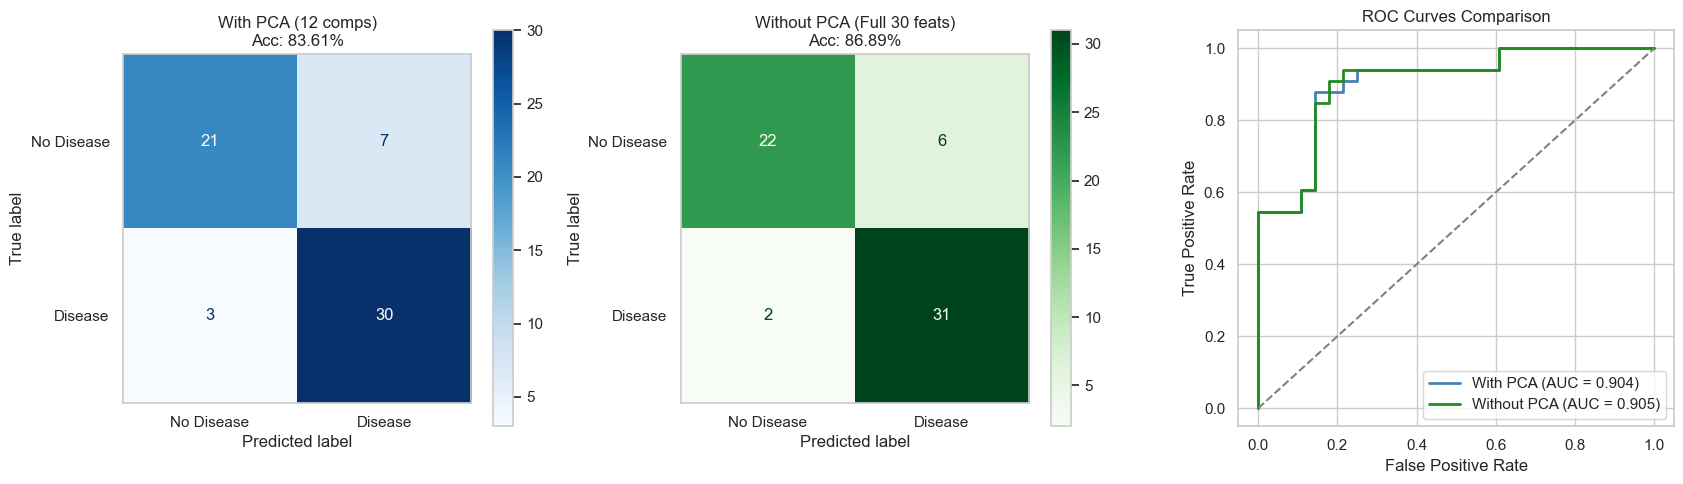

In [8]:
# 3. Visual Comparison: Confusion Matrices & ROC Curves
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Confusion Matrix: With PCA
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_pca,
    display_labels=['No Disease', 'Disease'],
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title(f"With PCA ({grid_pca.best_params_['pca__n_components']} comps)\nAcc: {accuracy_score(y_test, pred_pca):.2%}")
axes[0].grid(False)

# Confusion Matrix: Without PCA
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_no_pca,
    display_labels=['No Disease', 'Disease'],
    cmap='Greens',
    ax=axes[1]
)
axes[1].set_title(f"Without PCA (Full {X_preprocessed.shape[1]} feats)\nAcc: {accuracy_score(y_test, pred_no_pca):.2%}")
axes[1].grid(False)

# Comparative ROC Curves
fpr_pca, tpr_pca, _ = roc_curve(y_test, proba_pca)
fpr_nopca, tpr_nopca, _ = roc_curve(y_test, proba_no_pca)

axes[2].plot(fpr_pca, tpr_pca, color='steelblue', lw=2,
             label=f"With PCA (AUC = {roc_auc_score(y_test, proba_pca):.3f})")
axes[2].plot(fpr_nopca, tpr_nopca, color='forestgreen', lw=2,
             label=f"Without PCA (AUC = {roc_auc_score(y_test, proba_no_pca):.3f})")
axes[2].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("ROC Curves Comparison")
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()

---
## 6. PCA Explained Variance Analysis (Scree Plot)

To understand how much information each principal component retains, we plot the **Individual** and **Cumulative Explained Variance Ratio**.


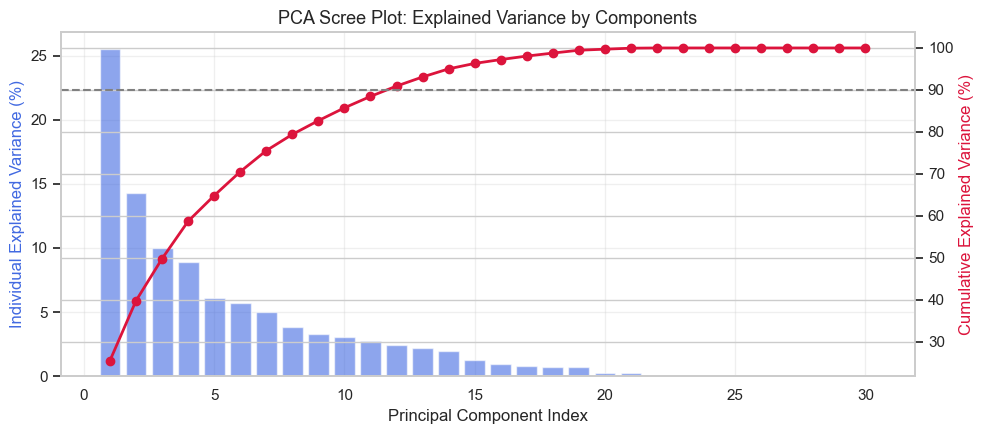

• 80% variance explained by top 9 components (out of 30 features).
• 85% variance explained by top 10 components (out of 30 features).
• 90% variance explained by top 12 components (out of 30 features).
• 95% variance explained by top 14 components (out of 30 features).


In [9]:
# Fit full PCA to preprocessed training data
pca_full = PCA().fit(X_preprocessed)
exp_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

fig, ax1 = plt.subplots(figsize=(10, 4.5))

# Bar plot of individual variance
ax1.bar(range(1, len(exp_var) + 1), exp_var * 100, alpha=0.6, color='royalblue', label='Individual Variance (%)')
ax1.set_xlabel("Principal Component Index")
ax1.set_ylabel("Individual Explained Variance (%)", color='royalblue')

# Line plot of cumulative variance
ax2 = ax1.twinx()
ax2.plot(range(1, len(cum_var) + 1), cum_var * 100, color='crimson', marker='o', lw=2, label='Cumulative Variance (%)')
ax2.axhline(90, color='gray', linestyle='--', label='90% Threshold')
ax2.set_ylabel("Cumulative Explained Variance (%)", color='crimson')

plt.title("PCA Scree Plot: Explained Variance by Components", fontsize=13)
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print milestones
for th in [80, 85, 90, 95]:
    n_comp = np.argmax(cum_var >= th/100) + 1
    print(f"• {th}% variance explained by top {n_comp} components (out of {len(exp_var)} features).")